# UCI Online Retail — Quickstart

Load the committed sample, profile it, and show three views:
1. RFM segmentation
2. Top countries & products
3. Returns rate

**Dataset**: [`samples/uci-online-retail-sample.csv`](../samples/uci-online-retail-sample.csv) — first 500 rows of UCI Online Retail (CC BY 4.0).

For the full 541K-row dataset, run `python scripts/fetch_samples.py uci` first.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

df = pd.read_csv('../samples/uci-online-retail-sample.csv', parse_dates=['InvoiceDate'])
print('Shape:', df.shape)
df.head()

Shape: (500, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. Profile the columns

In [2]:
print('Date range:', df['InvoiceDate'].min(), '→', df['InvoiceDate'].max())
print('Unique invoices:', df['InvoiceNo'].nunique())
print('Unique customers:', df['CustomerID'].nunique())
print('Unique countries:', df['Country'].nunique())
print('Nulls per column:')
print(df.isna().sum())

Date range: 2010-12-01 08:26:00 → 2010-12-01 11:45:00
Unique invoices: 45
Unique customers: 31
Unique countries: 4
Nulls per column:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


## 2. Top countries and products

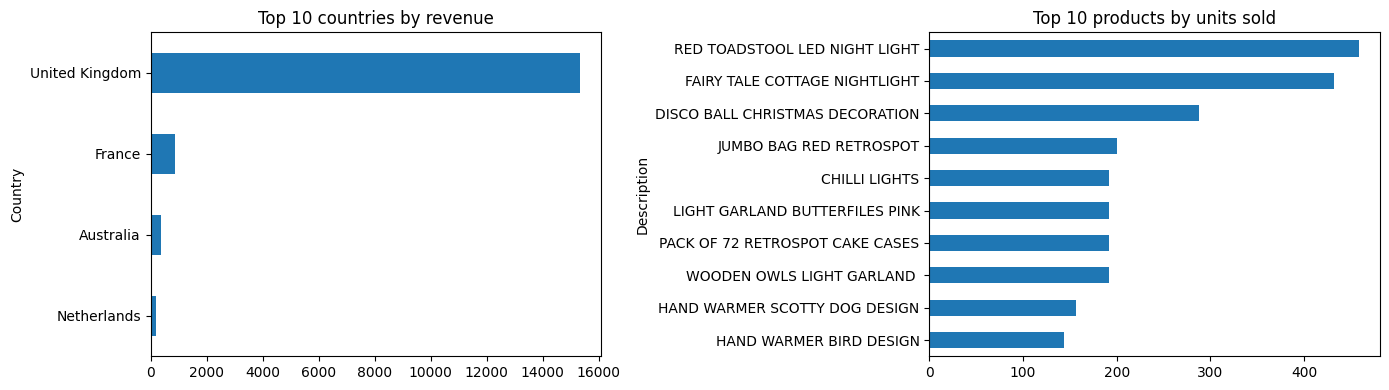

In [3]:
df['Revenue'] = df['Quantity'] * df['UnitPrice']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df.groupby('Country')['Revenue'].sum().nlargest(10).plot.barh(ax=axes[0], title='Top 10 countries by revenue')
df.groupby('Description')['Quantity'].sum().nlargest(10).plot.barh(ax=axes[1], title='Top 10 products by units sold')
axes[0].invert_yaxis(); axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

## 3. Returns rate

Cancellations have invoice numbers starting with `C`.

In [4]:
df['IsCancellation'] = df['InvoiceNo'].astype(str).str.startswith('C')

returns = df[df['IsCancellation']]
sales   = df[~df['IsCancellation']]

print(f'Sales rows:       {len(sales):,}')
print(f'Cancellation rows: {len(returns):,}')
print(f'Returns rate:     {len(returns) / len(df):.2%}')

if not returns.empty:
    print('\nTop returned products:')
    print(returns.groupby('Description')['Quantity'].sum().abs().nlargest(5))

Sales rows:       491
Cancellation rows: 9
Returns rate:     1.80%

Top returned products:
Description
PACK OF 12 BLUE PAISLEY TISSUES      24
PACK OF 12 PINK PAISLEY TISSUES      24
PACK OF 12 RED RETROSPOT TISSUES     24
PLASTERS IN TIN SKULLS               24
CHICK GREY HOT WATER BOTTLE          12
Name: Quantity, dtype: int64


## 4. RFM segmentation

Compute Recency / Frequency / Monetary per customer. With only 500 rows this is illustrative; rerun on the full file for real cohorts.

In [5]:
clean = df[(~df['IsCancellation']) & (df['CustomerID'].notna()) & (df['Quantity'] > 0)].copy()
snapshot = clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = clean.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum'),
).reset_index()

for col in ['Recency', 'Frequency', 'Monetary']:
    rfm[f'{col[0]}_quintile'] = pd.qcut(rfm[col].rank(method='first'), 5, labels=[5,4,3,2,1] if col == 'Recency' else [1,2,3,4,5])

rfm['RFM_Score'] = rfm['R_quintile'].astype(int) + rfm['F_quintile'].astype(int) + rfm['M_quintile'].astype(int)
rfm.sort_values('RFM_Score', ascending=False).head(10)

,CustomerID,Recency,Frequency,Monetary,R_quintile,F_quintile,M_quintile,RFM_Score
5,13448.0,1,2,443.96,5,5,4,14
3,13047.0,1,3,366.63,5,5,3,13
18,16029.0,1,2,3702.12,2,5,5,12
1,12583.0,1,1,855.86,5,1,5,11
25,17850.0,1,10,1499.34,1,5,5,11
4,13408.0,1,1,1024.68,5,1,5,11
11,14307.0,1,1,783.11,4,2,5,11
28,18074.0,1,1,489.60,1,5,4,10
23,17511.0,1,1,1825.74,1,4,5,10
20,16218.0,1,1,471.30,2,4,4,10


## What to try next
- Run on the full UCI file (541K rows) — `python scripts/fetch_samples.py uci`.
- Add `IsWholesale` flag (Quantity > 10 or Revenue > £200).
- Build cohort retention curves grouped by first-purchase month.
- Read [`scorecards/01-customer-health-rfm.md`](../scorecards/01-customer-health-rfm.md) for the metrics framework.